<a href="https://colab.research.google.com/github/Wilkelson/A01724709-Repository/blob/main/A7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

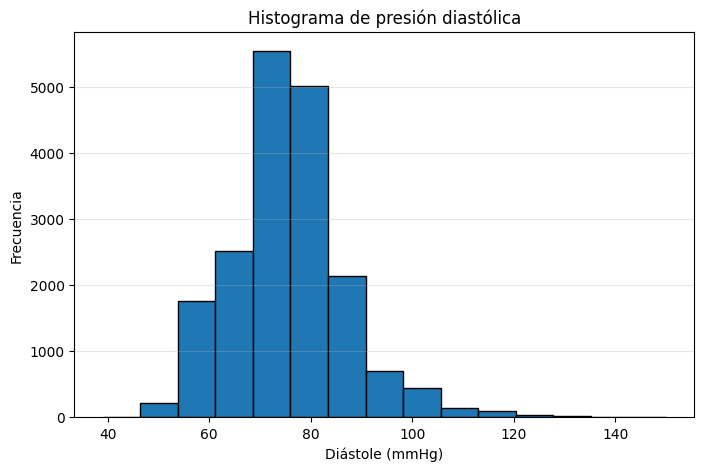

In [10]:
import pandas as pd
import matplotlib.pyplot as plt


col = "diastol"

plt.figure(figsize=(8, 5))
plt.hist(df[col].dropna(), bins=15, edgecolor="black")
plt.title("Histograma de presión diastólica")
plt.xlabel("Diástole (mmHg)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.show()

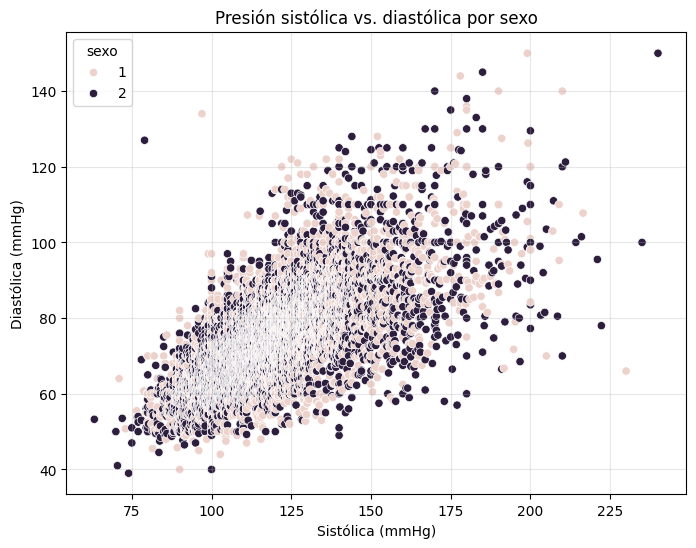

In [11]:

import seaborn as sns




plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="sistol", y="diastol", hue="sexo")
plt.title("Presión sistólica vs. diastólica por sexo")
plt.xlabel("Sistólica (mmHg)")
plt.ylabel("Diastólica (mmHg)")
plt.grid(alpha=0.3)
plt.show()

In [12]:



mujer_cintura = df.loc[df["sexo"] == 2, "cintura"].dropna()


q1 = mujer_cintura.quantile(0.25)
q3 = mujer_cintura.quantile(0.75)
iqr = q3 - q1

limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

atipicos = mujer_cintura[(mujer_cintura < limite_inf) | (mujer_cintura > limite_sup)]

print("Límites:", limite_inf, limite_sup)
print("¿Hay valores atípicos en mujer_cintura?", len(atipicos) > 0)
print("Cantidad de atípicos:", len(atipicos))
print(atipicos.values)

Límites: 44.17499999999999 129.975
¿Hay valores atípicos en mujer_cintura? True
Cantidad de atípicos: 86
[222.2  222.2  222.2  130.5  222.22 131.8  143.2  222.21 222.22 145.25
 222.22 139.5  222.22 222.22 222.2  135.   222.21 157.45 132.7  149.7
 222.22 222.21 222.22 147.45 130.9  168.65 222.22 138.2  222.22 222.2
 222.21 222.2  146.2  222.2  222.21 222.21 130.95 133.3  133.   222.22
 222.2  149.8  156.1  136.8  141.   222.21 131.7  136.25  34.55 134.7
 131.   152.2  144.9  134.7  138.3  130.2  142.6  130.   147.9  130.05
 222.2  135.5  134.   222.22 130.45 222.2  131.   137.1  134.3  154.55
 132.65 222.21 222.21 222.21 130.05 132.65 131.   147.55 132.1  222.2
 222.2  136.6  130.05 161.8  133.   222.21]


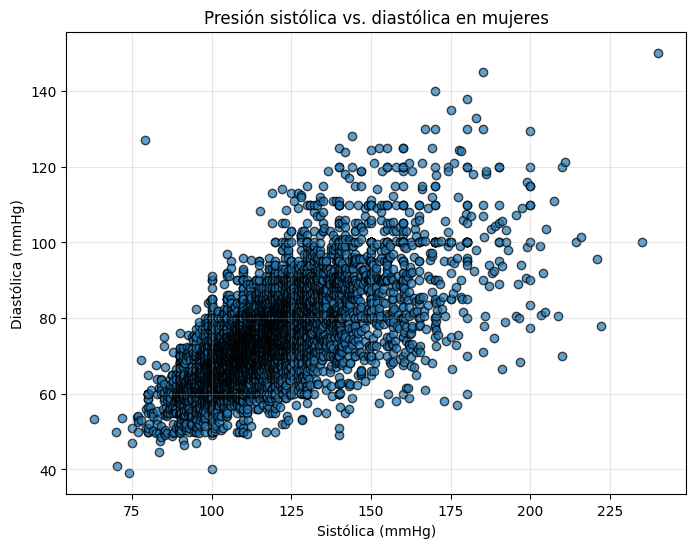

In [13]:
mujeres = df[df["sexo"] == 2]

mujer_sistol = mujeres["sistol"]
mujer_diastol = mujeres["diastol"]

plt.figure(figsize=(8, 6))
plt.scatter(mujer_sistol, mujer_diastol, alpha=0.7, edgecolor="black")
plt.title("Presión sistólica vs. diastólica en mujeres")
plt.xlabel("Sistólica (mmHg)")
plt.ylabel("Diastólica (mmHg)")
plt.grid(alpha=0.3)
plt.show()

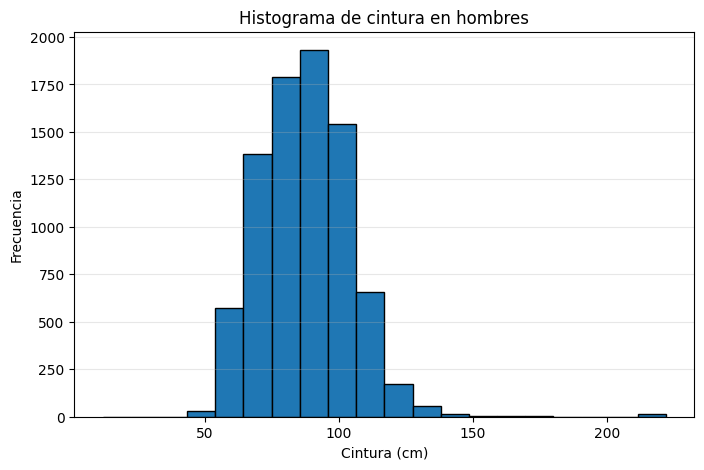

In [14]:
hombre_cintura = df.loc[df["sexo"] == 1, "cintura"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(hombre_cintura, bins=20, edgecolor="black")
plt.title("Histograma de cintura en hombres")
plt.xlabel("Cintura (cm)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [15]:

datos = df[["cadera", "peso"]].dropna()

X = sm.add_constant(datos["peso"])   # agrega b0
y = datos["cadera"]

modelo = sm.OLS(y, X).fit()

print(modelo.summary())
print("R-squared:", modelo.rsquared)
print("b0:", modelo.params["const"])
print("b1:", modelo.params["peso"])

                            OLS Regression Results                            
Dep. Variable:                 cadera   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                 2.748e+04
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:22:58   Log-Likelihood:                -65165.
No. Observations:               18032   AIC:                         1.303e+05
Df Residuals:                   18030   BIC:                         1.304e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         57.4600      0.252    228.032      0.0

In [16]:
correlacion = df['peso'].corr(df['cadera'])
print("Coeficiente de correlación:", correlacion)

Coeficiente de correlación: 0.7770606658014013


In [17]:
from statsmodels.stats.stattools import durbin_watson
import statsmodels.api as sm

X = sm.add_constant(df['sistol'])
y = df['diastol']

modelo = sm.OLS(y, X).fit()

dw = durbin_watson(modelo.resid)
print("Durbin-Watson:", dw)

Durbin-Watson: 1.7463985152850534


In [24]:
columnas = ['diastol', 'sistol', 'edad', 'peso', 'cintura']

df_reg = df[columnas].replace([np.inf, -np.inf], np.nan).dropna()

X = df_reg[['sistol', 'edad', 'peso', 'cintura']]
X = sm.add_constant(X)
y = df_reg['diastol']

modelo = sm.OLS(y, X).fit()

print("b0 =", modelo.params['const'])

b0 = 20.32967638696536


In [25]:
df_reg = df[['cadera', 'peso']].dropna()

X = sm.add_constant(df_reg['peso'])
y = df_reg['cadera']

modelo = sm.OLS(y, X).fit()

print("Mediana de los residuos:", modelo.resid.median())

Mediana de los residuos: -0.6495739811776744
